# Geopolitical Exposure Through Text and Holdings Embeddings
## Presentation summary of the Russia–Ukraine proof of concept

**Research question.** Can a small set of firm exposures extracted from pre-event disclosures be expanded through holdings-based asset embeddings to identify economically related firms—and do those expanded scores explain cross-sectional stock reactions to a geopolitical shock?

This notebook reports the complete proof of concept, including unsuccessful tests. It is designed to render as a self-contained report without rerunning SEC downloads, OpenAI extraction, embedding propagation, or the event study.


## Executive conclusion

The experiment supports a **representation and discovery** claim more strongly than an **event-return prediction** claim.

1. A conservative, evidence-audited language-model pipeline extracted 133 accepted firm–channel exposures from pre-invasion SEC filings. Every accepted label has an exact source quotation.
2. Holdings embeddings recovered some withheld text labels internally. Recovery was strongest for oil and gas, shipping/logistics, and Russia/Ukraine operating exposure, but the best embedding depended on the channel.
3. The expanded all-S12 scores did **not** robustly explain invasion-event abnormal returns after characteristics, industry controls, shuffled-seed placebos, and multiple-testing corrections. Zero of 105 model–channel–window specifications passed the joint screen.
4. Several V1 event associations changed materially after expanding from the original 50-firm pilot. This indicates seed-set sensitivity and makes the expanded negative result especially informative.

> **Bottom line:** holdings embeddings can transmit selected text-defined economic relationships across firms, but this experiment does not establish that those transmitted scores predict Russia–Ukraine event returns. A separately designed, held-out event is required for an independent confirmation.


## 1. Motivation and relation to the asset-embeddings paper

Gabaix, Koijen, Richmond, and Yogo develop asset embeddings as learned firm representations from portfolio holdings. Their July 16, 2026 paper argues that investors' portfolios contain information beyond conventional accounting and market characteristics and adapts recommender systems, Word2Vec, and transformer methods to holdings data. The paper also uses large language models to interpret neighborhoods in holdings-embedding space: firm-level text is summarized, and common themes are sought among firms that are close in the learned space. See [Gabaix et al., *Asset and Investor Embeddings*](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5212742), DOI [10.2139/ssrn.5212742](https://doi.org/10.2139/ssrn.5212742).

This extension changes the task. It does not merely ask an LLM to narrate an existing cluster. Instead, it:

- defines an ex ante geopolitical scenario;
- extracts firm-specific scenario exposures from pre-event filings;
- treats those directly labeled firms as seeds;
- propagates the signed labels through holdings-based embeddings; and
- evaluates both semantic recovery and event-return associations.

The use of firm text to measure political exposure also relates to Hassan, Hollander, van Lent, and Tahoun, who construct firm-level political-risk measures from earnings-call language and show that much of the variation is firm-specific rather than purely sectoral. See [Hassan et al. (2019), *Quarterly Journal of Economics*](https://doi.org/10.1093/qje/qjz021). Our documents, extraction method, and target construct differ: we use SEC filings, evidence-constrained LLM extraction, and predefined Russia–Ukraine channels.


## 2. Research design and chronology

The experiment proceeded in four layers.

| Layer | Question | Information allowed | Principal output |
|---|---|---|---|
| Text corpus | What did firms disclose before the invasion? | SEC filings available by 2022-02-23 | Normalized 10-K/10-Q corpus |
| Direct labels | Which disclosures support predefined scenario channels? | Retrieved passages only | Evidence-audited firm–channel labels |
| Embedding expansion | Which other firms are close to the labeled firms in holdings space? | 2021Q4 holdings embeddings and pre-event characteristics | Full-universe channel scores |
| Event evaluation | Did the scores align with market reactions? | CRSP returns opened only after V2 propagation was frozen | CAR correlations, controlled regressions, placebos |

The V2 propagation notebook explicitly recorded `OUTCOMES_LOADED=False` and hashed its inputs and outputs before loading event returns. However, the same Russia–Ukraine event had already been examined in the earlier V1 pilot. Therefore, V2 is correctly described as an **expanded-sample robustness analysis**, not a fully independent confirmation.


## 3. Scenario definition

The focal event was Russia's invasion of Ukraine on **February 24, 2022**. The information cutoff was **February 23, 2022**. Holdings were measured using the **2021Q4** embeddings. The predefined channels were:

| Channel | Expected direction | Interpretation |
|---|---:|---|
| Russia/Ukraine operations and revenue | Negative | Operations, customers, revenue, assets, or facilities tied to Russia or Ukraine |
| European energy dependence | Negative | Dependence on European energy supply or pricing |
| Oil and gas production | Positive | Potential benefit from higher energy prices or replacement supply |
| Defense demand | Positive | Demand from defense agencies or military systems |
| Agriculture and fertilizer | Ambiguous | Commodity benefits versus input and supply disruption |
| European banking and sanctions | Negative | Financial intermediation or sanctions exposure |
| Shipping and logistics | Negative | Freight, port, route, and distribution disruption |
| Sanctions-sensitive supply chain | Negative | Operations or supply chains vulnerable to sanctions and export controls |

Channels with no defensible direct labels were not forced into the downstream analysis. The two agriculture/fertilizer labels remained directionally ambiguous and were preserved in the audit but excluded from directional propagation.


## 4. Frozen firm selection and SEC corpus

The expanded sample retained all 50 original pilot firms and selected 250 additional firms across 54 SIC2 industries, five size quintiles, and 20 clusters from the pre-event all-S12 embedding. Event returns did not enter selection.

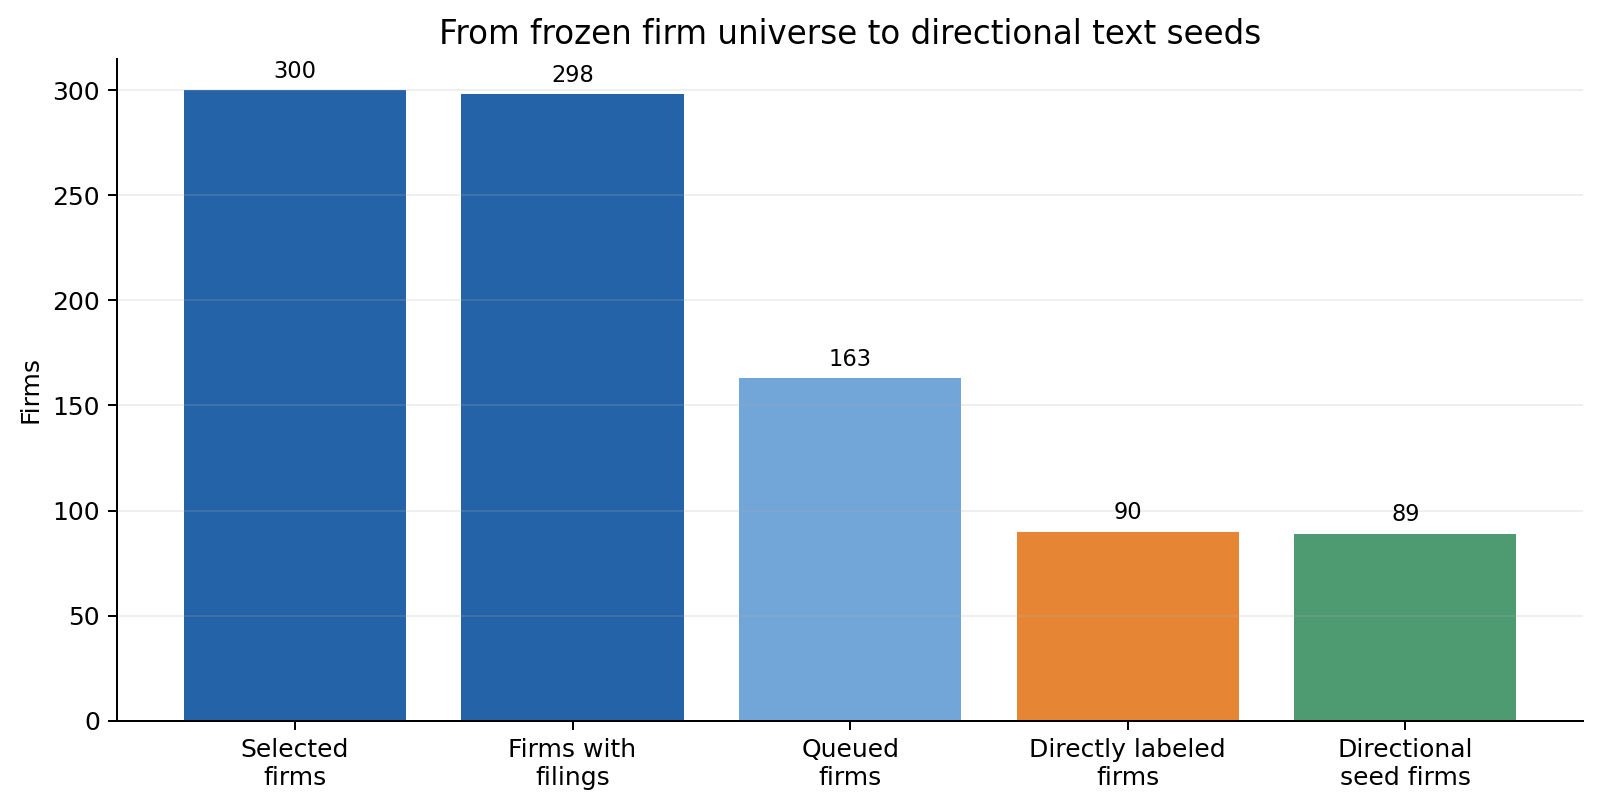

| Corpus statistic | Result |
|---|---:|
| Frozen firms | 300 |
| Firms with eligible filings | 298 |
| Eligible filing metadata rows | 10,752 |
| Selected documents | 477 |
| Selected 10-K filings | 298 |
| Selected 10-Q filings | 179 |
| Document download/normalization errors | 0 |
| Documents with retrieved scenario passages | 196 |
| Firms represented in API queue | 163 |
| Approximate queued input tokens before extraction | 317,109 |

For each firm, the deterministic document rule selected the latest eligible 10-K and, when available, the latest subsequent 10-Q. Raw HTML, normalized text, filing metadata, and retrieval records were stored locally. The SEC provides public filing access through EDGAR and documents programmatic access through its [developer resources](https://www.sec.gov/about/developer-resources). The acquisition code used an identifying user agent, local checkpoints, and moderated requests consistent with the SEC's fair-access guidance.


## 5. Passage retrieval

Full filings were not sent wholesale to the language model. A deterministic retrieval stage searched for a frozen dictionary covering geography, sanctions, energy, defense, agriculture, and logistics. Around each match, the pipeline retained a bounded source window and capped retrieval at 30 passages per document.

This served three purposes:

- **Cost control:** only potentially relevant text entered the API queue.
- **Auditability:** every model statement could be checked against a limited passage set and then against the full normalized filing.
- **Conservatism:** documents without a keyword-supported passage were treated as unlabeled, not automatically as zero-exposure firms.

Of 477 selected documents, 196 had at least one retrieved passage. The median across all documents was zero passages, while the maximum was 30. This intentionally favors precision over recall.


## 6. Exact OpenAI extraction prompt

The following instruction string was sent unchanged with every queued document. The dynamic input contained only the firm identifier, document identifier, scenario identifier, frozen channel definitions, and retrieved passages. No returns, company outcome, or outside search context was supplied.

```text
You are a conservative research-data extractor. Use only the supplied
pre-event document passages. Do not use outside knowledge or infer exposure from the company
name. Return an exposure only when the quoted text directly supports the specified channel and
direction. A material disclosed business relationship to a channel—such as revenue, customers,
operations, assets, production, or facilities—counts as exposure even if the filing predates and
does not name the future event. Evidence must be an exact, shortest self-contained quote of no
more than 1000 characters from the supplied passage. If nothing is supported, set
no_supported_exposure=true and return an empty exposures array. A company name, patent
jurisdiction, generic compliance language, or generic industry membership without a disclosed
business relationship is not by itself evidence of scenario exposure. evidence_start and
evidence_end must be offsets in the original document, computed from the supplied passage start
plus the quote's location in that passage.
```

The per-document payload had this structure:

```json
{
  "firm_id": "<PERMCO>",
  "document_id": "<SEC accession number>",
  "scenario_id": "russia_ukraine_invasion_2022",
  "channel_definitions": ["<the eight frozen channel objects>"],
  "passages": ["<retrieved source passages with offsets>"]
}
```

Extraction used the OpenAI Responses API with model `gpt-5.6-luna`, low reasoning effort, `store=False`, and strict JSON-schema output. OpenAI's API documentation describes Responses as supporting text or JSON outputs, and recommends JSON Schema for strict structured output on supported models: [Responses API](https://developers.openai.com/api/reference/cli/resources/responses/methods/create) and [JSON-schema response format](https://platform.openai.com/docs/api-reference/responses-streaming/response/refusal?lang=python). The complete frozen schema is available in [`schemas/exposure_output_schema.json`](schemas/exposure_output_schema.json).


## 7. Structured-output contract and reproducibility

Each response was required to contain:

- the original firm, document, and scenario identifiers;
- `no_supported_exposure`;
- an array of zero or more exposures; and
- for every exposure: channel, direction, score, confidence, exact evidence, offsets, and a short reasoning summary.

The queue, firm selection, prompt, schema, model, and `store=False` setting were hashed and frozen. Each response was written immediately to its own JSON checkpoint. Interrupted execution therefore resumed from the first unfinished document rather than resubmitting completed calls.

| API statistic | Result |
|---|---:|
| Documents processed | 196 |
| API failures | 0 |
| Actual input tokens | 381,772 |
| Actual output tokens | 187,158 |
| Total tokens | 568,930 |
| Response-level contract failures | 0 |
| Initial exposure candidates | 134 |


## 8. Evidence validation and adjudication

Structured output guarantees field shape, not factual grounding. The pipeline therefore applied separate evidence gates:

1. response model, prompt hash, schema hash, and queue hash matched the frozen contract;
2. returned firm and document identifiers matched the queued record;
3. the stored source-content hash matched the normalized filing;
4. channel, direction, score, and confidence were valid;
5. every evidence quotation occurred exactly in the retrieved filing text and was no longer than 1,000 characters.

Twelve of 134 candidates initially failed only the exact-quotation test because the model slightly reconstructed spacing or sentence boundaries. These were never silently accepted. Seven received source-exact algorithmic repairs, four received explicitly bounded exact source spans, and one generic sanctions statement was rejected for insufficient scenario specificity.

| Final decision | Candidates |
|---|---:|
| Original exact model quotation | 122 |
| Accepted algorithmic exact repair | 7 |
| Accepted manually bounded exact span | 4 |
| Rejected for insufficient specificity | 1 |
| **Final accepted exposures** | **133** |

The final panel contains 90 directly labeled firms across 107 documents, and every accepted quotation passes the exact-source gate.

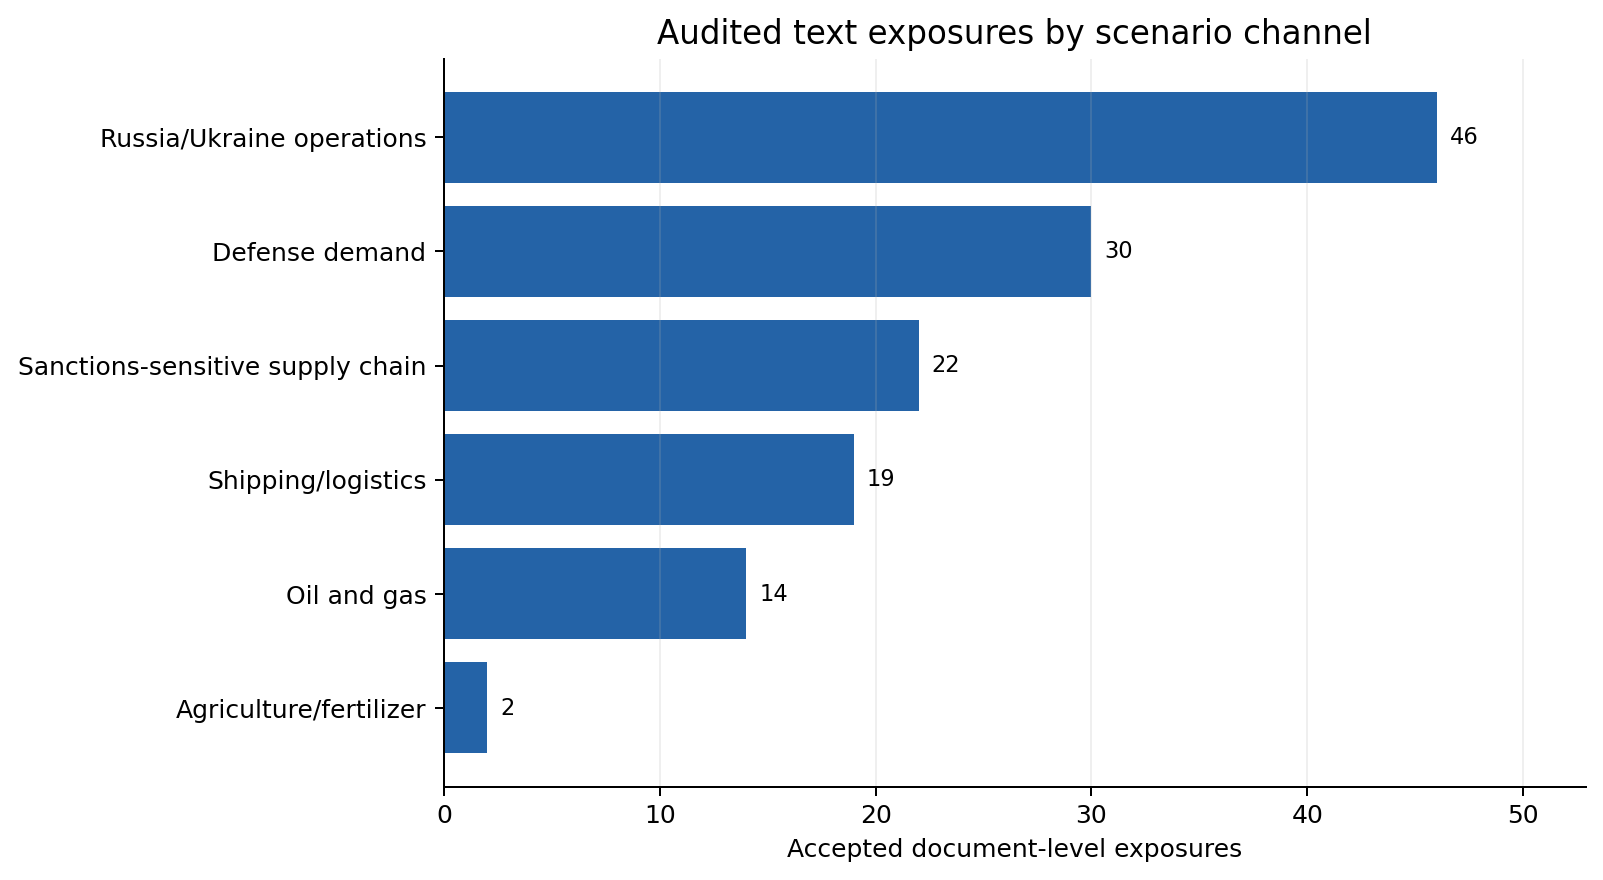


## 9. Converting document labels into embedding seeds

Document-level labels were collapsed to unique firm–channel seeds. For firm `a` and channel `c`, repeated disclosures were combined as a confidence-weighted signed score:

$$s_{ac}=\frac{\sum_d s_{acd}q_{acd}}{\sum_d q_{acd}},$$

where $s_{acd}$ is the signed document score and $q_{acd}$ is model confidence. This produced 112 directional firm–channel seeds across 89 firms. Two ambiguous agriculture/fertilizer labels were retained separately and excluded from directional propagation.

For each representation, firm embeddings were row-normalized. A channel score for any firm `a` was calculated from cosine similarity to the channel's seed firms:

$$\widehat{s}_{ac}=\frac{\sum_{j\in S_c}\cos(x_a,x_j)s_{jc}q_{jc}}{\sum_{j\in S_c}|s_{jc}q_{jc}|}.$$

The denominator normalizes total signed seed mass. Seed firms were flagged and excluded from discovery rankings and from the final non-seed event study.


## 10. Representations and benchmarks

All representations used the same 1,805-firm 2021Q4 universe.

| Representation | Role |
|---|---|
| All-S12 RS-Binary 10D | Primary holdings-embedding expansion |
| Stable-stock-picker RS-Binary 10D | Holdings of behaviorally stable stock pickers |
| Tactical-active RS-Binary 10D | Holdings of tactically active investors |
| Benchmark-rebalancer RS-Binary 10D | Holdings of benchmark-like rebalancers |
| Passive-like RS-Binary 10D | Holdings of passive-like investors |
| Characteristics similarity | Six conventional pre-event firm characteristics |
| Industry similarity | SIC2 average of signed seed exposures |
| Shuffled-seed placebo | Identical weights assigned to random non-seed firms |

The holdings-embedding motivation follows the core argument in [Gabaix et al.](https://doi.org/10.2139/ssrn.5212742): portfolios encode investor information and can generate useful learned representations of firms. Our scenario propagation rule is an extension designed for this project; it is not a procedure claimed or evaluated in their paper.


## 11. Outcome-free internal validation

Each directional seed was predicted while excluding itself from the seed set. This leave-one-seed-out test asks whether a representation places firms with similar independently extracted exposures near one another. It does not use returns.

| Channel | Best representation | Seed predictions | Spearman correlation |
|---|---|---:|---:|
| Defense demand | Benchmark rebalancer | 22 | 0.268 |
| Oil and gas production | Passive-like | 13 | 0.593 |
| Russia/Ukraine operations | Stable stock picker | 39 | 0.359 |
| Sanctions-sensitive supply chain | Characteristics | 21 | -0.124 |
| Shipping/logistics | All-S12 | 17 | 0.531 |

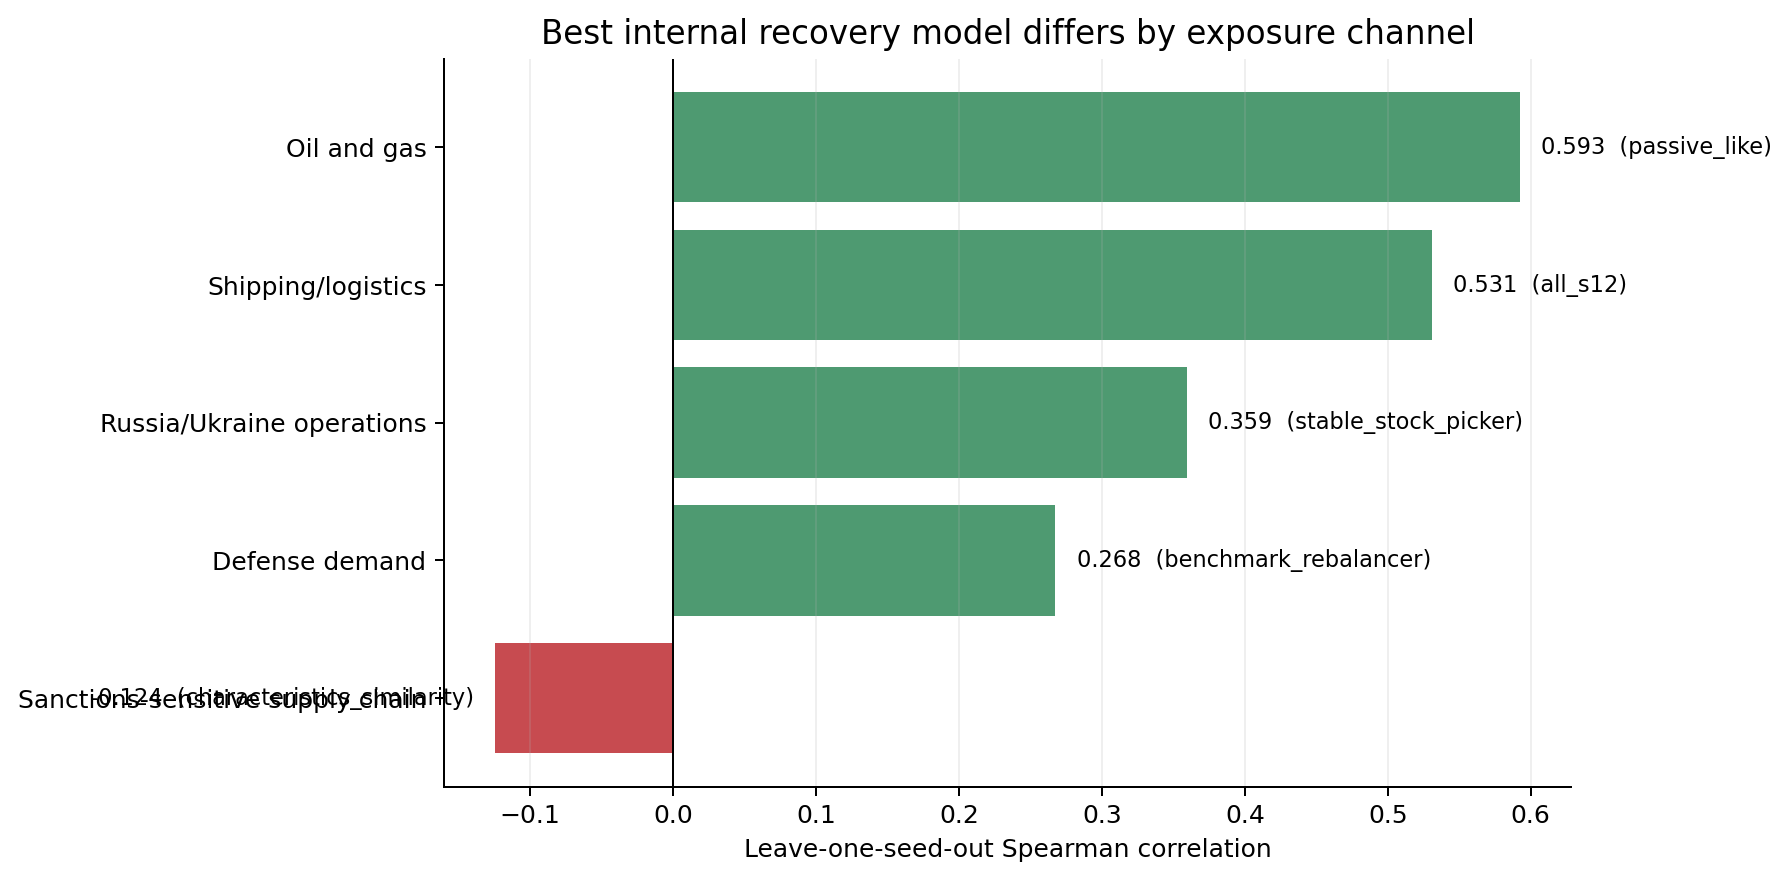

Oil and gas and shipping exposures show the clearest internal neighborhood structure. Sanctions-sensitive supply chains are not recovered reliably. Sign accuracy is not emphasized because labels within a channel almost always share the same expected direction, making a same-sign prediction mechanically easy. Rank correlation and absolute error are more informative.


## 12. Event-study methodology

Event studies estimate the effect of an economic event through security prices around the event date; the standard methodology and its complications are reviewed by [MacKinlay (1997)](https://econpapers.repec.org/article/aeajeclit/v_3a35_3ay_3a1997_3ai_3a1_3ap_3a13-39.htm) and by [Campbell, Lo, and MacKinlay (1997)](https://doi.org/10.1515/9781400830213-008).

Our implementation:

- aggregates PERMNO returns to PERMCO using lagged-market-equity weights;
- estimates a firm market model against the CRSP value-weighted market return;
- uses estimation window `[-250,-30]` trading days with at least 120 observations;
- measures CARs over `[0,1]`, `[0,5]`, and `[1,20]`;
- excludes all 89 directional seed firms from every propagated-score test; and
- holds the non-seed sample constant at approximately 1,700 firms per outcome.

For every model, channel, and window, the notebook reports:

1. Spearman score–CAR correlation;
2. top-minus-bottom score-quintile CAR;
3. a regression coefficient after six pre-event characteristics and SIC2 fixed effects; and
4. incremental adjusted $R^2$ relative to the controlled baseline.

HC3 heteroskedasticity-robust standard errors were used. Benjamini–Hochberg false-discovery-rate adjustments were applied over the transparent 105-specification grid; see [Benjamini and Hochberg (1995)](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x).


## 13. Event-study results

Many raw rank correlations are statistically small in conventional p-value terms, but that alone is not sufficient. The decisive checks are whether the score contributes beyond characteristics and industry, whether it exceeds the shuffled-seed distribution, and whether it survives multiple testing.

The strongest all-S12 result was oil and gas over `[0,1]`:

| Statistic | Result |
|---|---:|
| Spearman correlation | -0.224 |
| Raw Spearman p-value | < 0.001 |
| Placebo-adjusted two-sided p-value | 0.089 |
| Controlled score coefficient | -0.0011 |
| Controlled coefficient p-value | 0.565 |
| Incremental adjusted $R^2$ | -0.00038 |

It is suggestive but fails the predeclared joint standard. No all-S12 channel/window result achieved placebo-adjusted $p<0.05$.

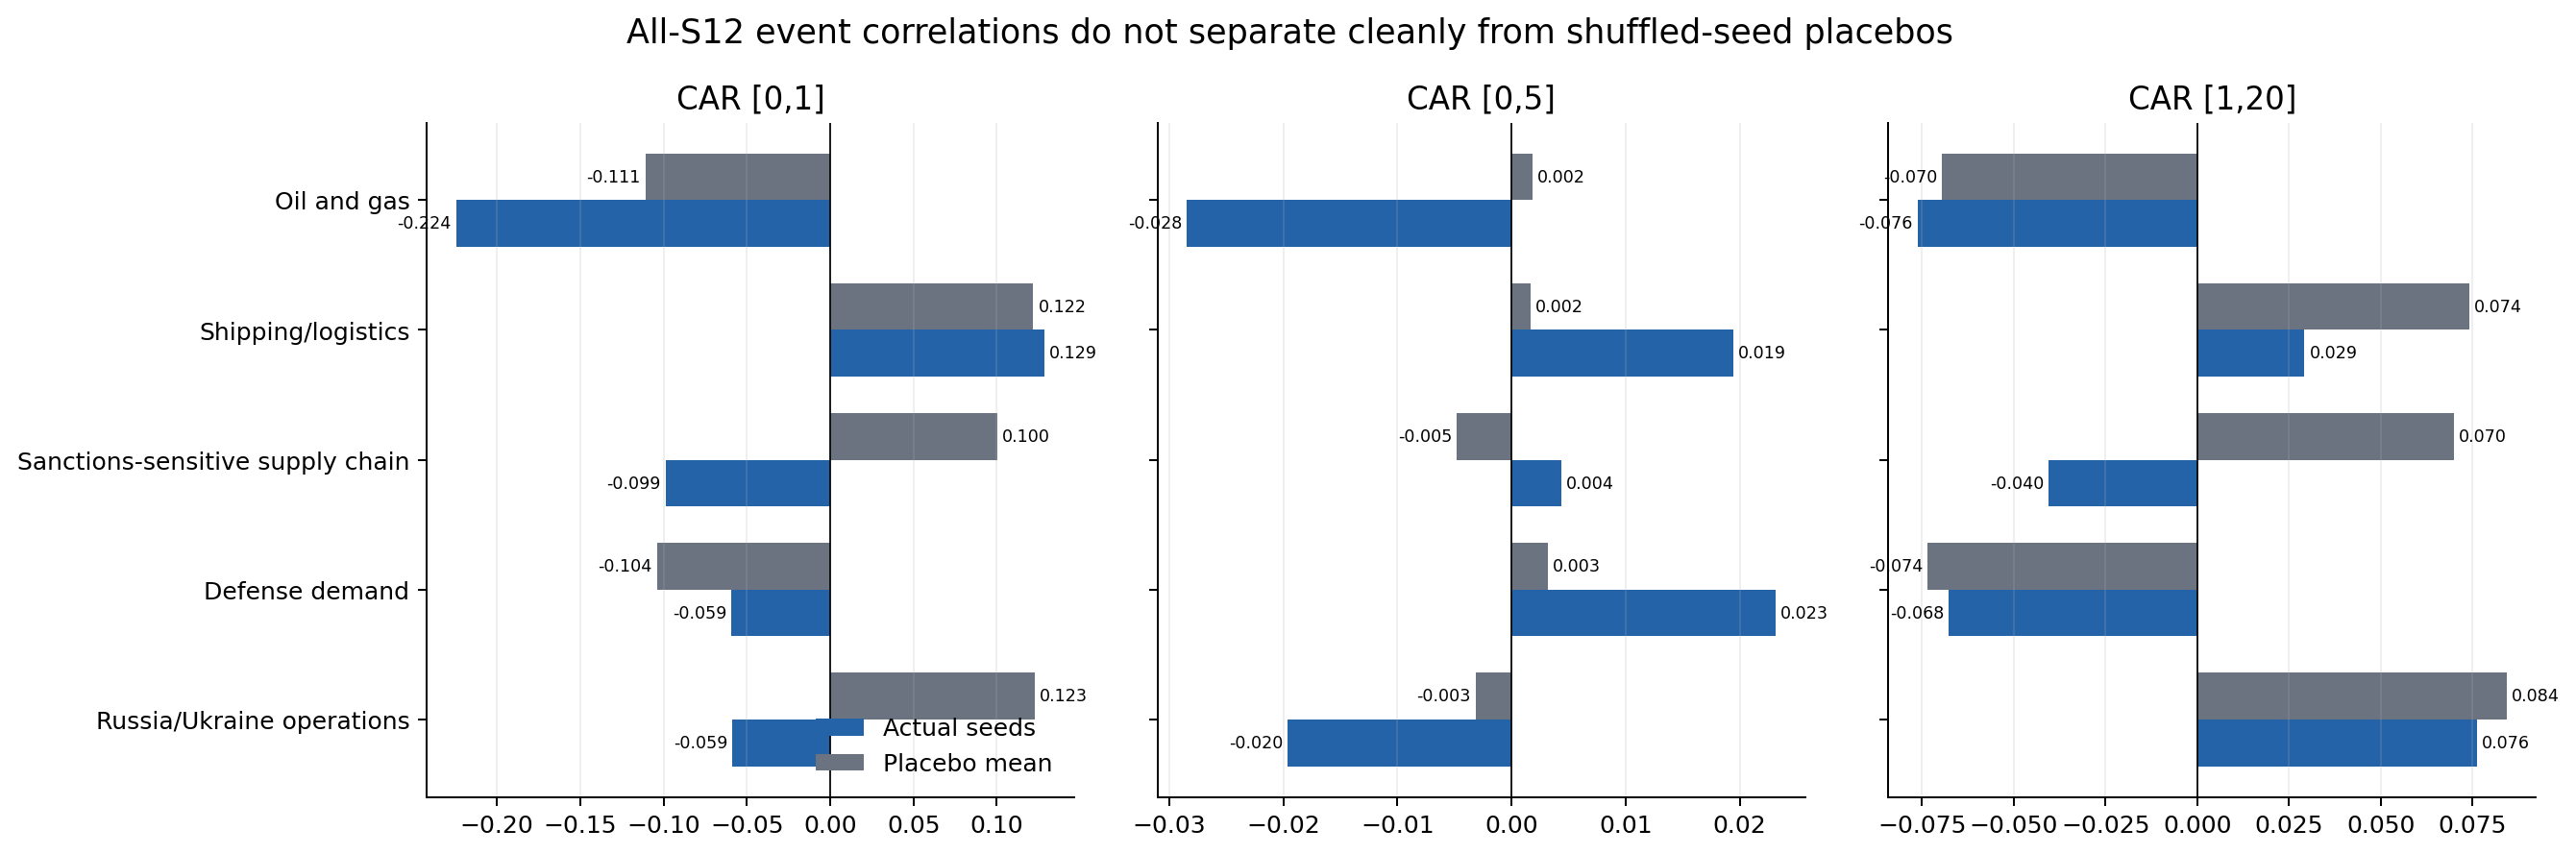

The nonzero placebo means are informative. Random seed sets can inherit systematic relations between the geometry of an embedding and event returns. This is precisely why raw score–return correlations cannot by themselves validate a scenario-discovery method.


## 14. Direct-text benchmark

The directly labeled firms provide a descriptive text-only benchmark. Sample sizes are modest—13 to 39 directional seeds per channel—and none of the direct score–CAR correlations were statistically significant.

| Channel | Largest absolute direct correlation | Window | p-value |
|---|---:|---|---:|
| Defense demand | -0.139 | `[0,5]` | 0.537 |
| Oil and gas | -0.392 | `[0,1]` | 0.185 |
| Russia/Ukraine operations | 0.201 | `[1,20]` | 0.221 |
| Sanctions-sensitive supply chain | 0.335 | `[1,20]` | 0.137 |
| Shipping/logistics | 0.247 | `[0,1]` | 0.339 |

This does not show that text is useless. It shows that the particular signed scores, sample size, and event windows do not deliver a precise return relationship in this proof of concept. The direct-text and propagated tests answer different questions: direct text concerns labeled firms; propagation concerns whether embeddings identify related unlabeled firms.


## 15. Why V1 and V2 differ

The original 50-firm pilot was useful for proving that the pipeline could run, but several event associations were not stable after label expansion.

| Shared channel | Window | V1 all-S12 $\rho$ | V2 all-S12 $\rho$ | Change |
|---|---|---:|---:|---:|
| Defense demand | `[0,1]` | -0.273 | -0.059 | +0.214 |
| Oil and gas | `[0,1]` | -0.030 | -0.224 | -0.194 |
| Russia/Ukraine operations | `[0,1]` | 0.097 | -0.059 | -0.156 |
| Oil and gas | `[1,20]` | 0.105 | -0.076 | -0.181 |
| Russia/Ukraine operations | `[1,20]` | 0.048 | 0.076 | +0.028 |

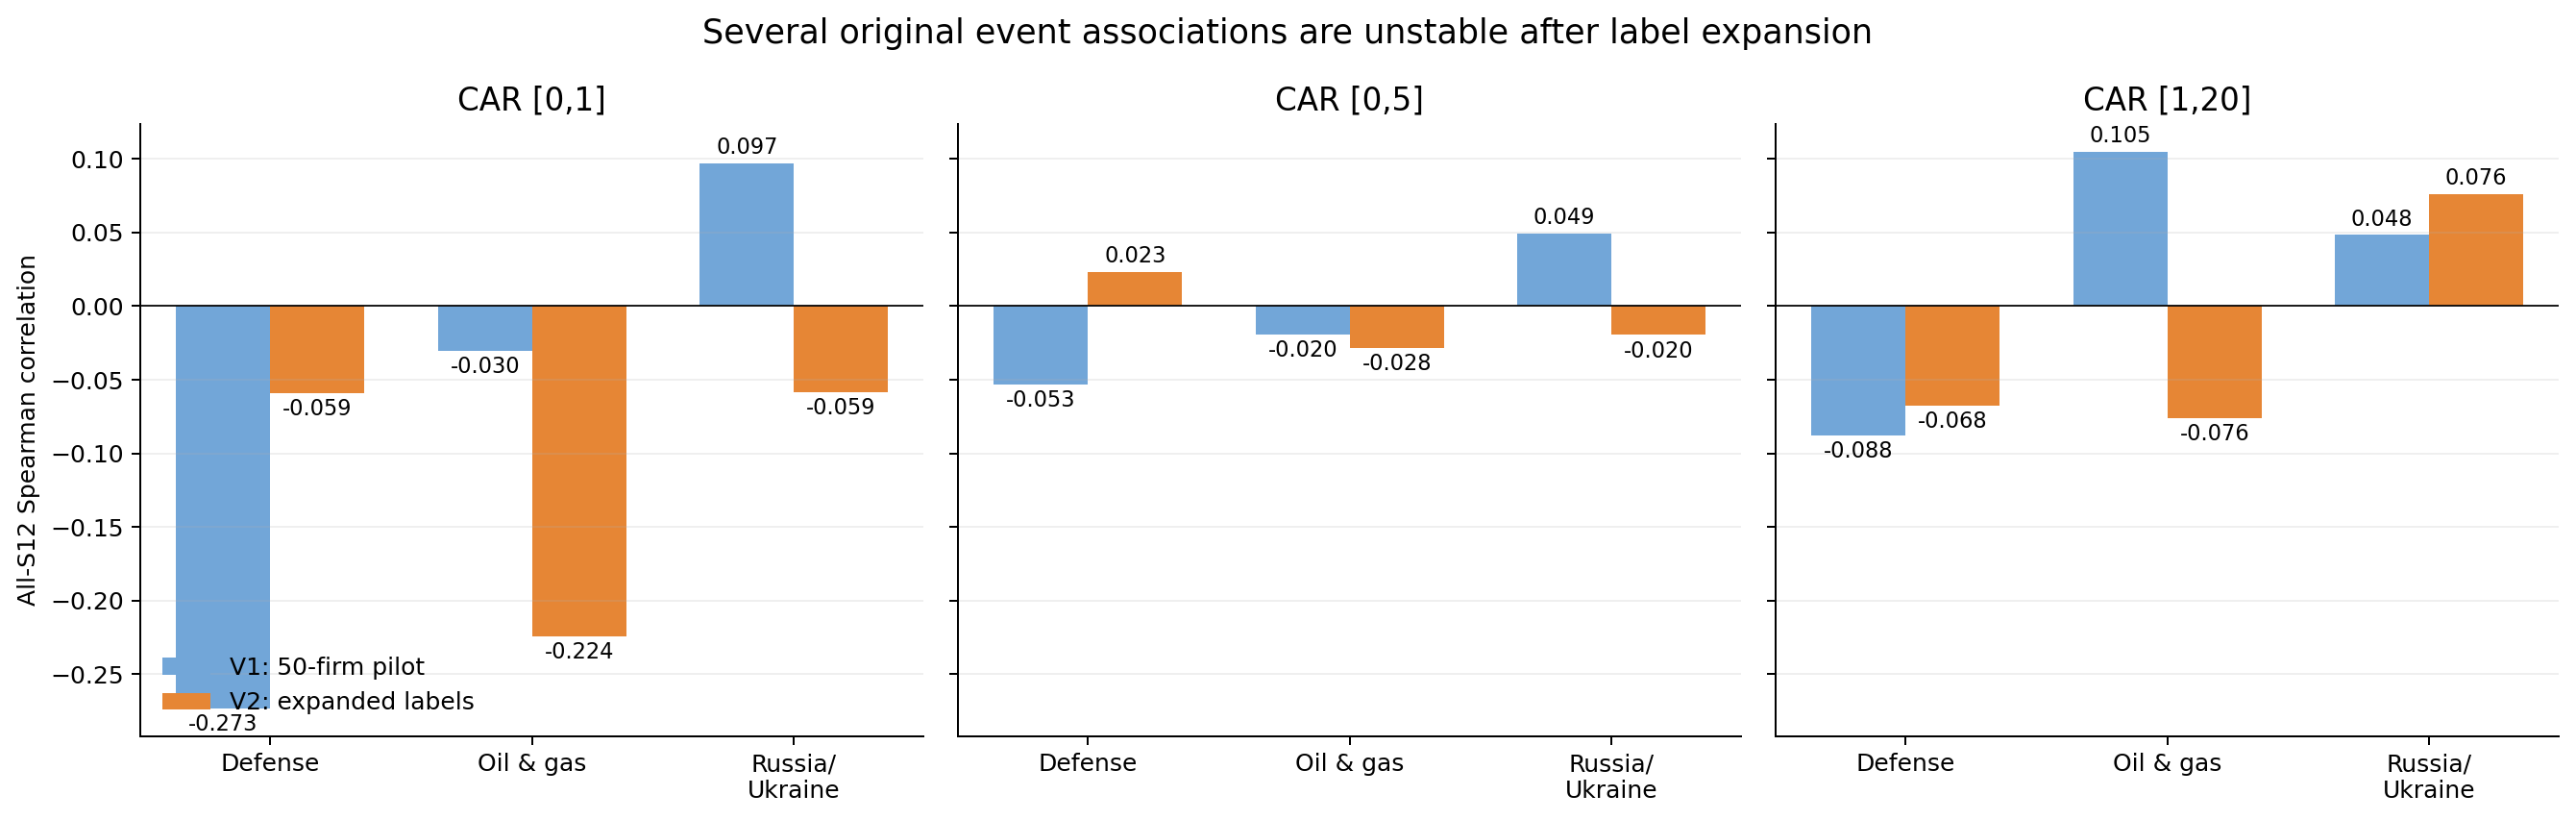

This instability is evidence that a small seed set can determine the apparent direction and composition of an embedding expansion. The expanded result should therefore replace—not be averaged with—the original pilot when describing evidence from this event.


## 16. Predeclared decision screen

A result passed only if it simultaneously had:

- an FDR-adjusted rank signal;
- an FDR-adjusted controlled regression signal; and
- positive incremental adjusted $R^2$.

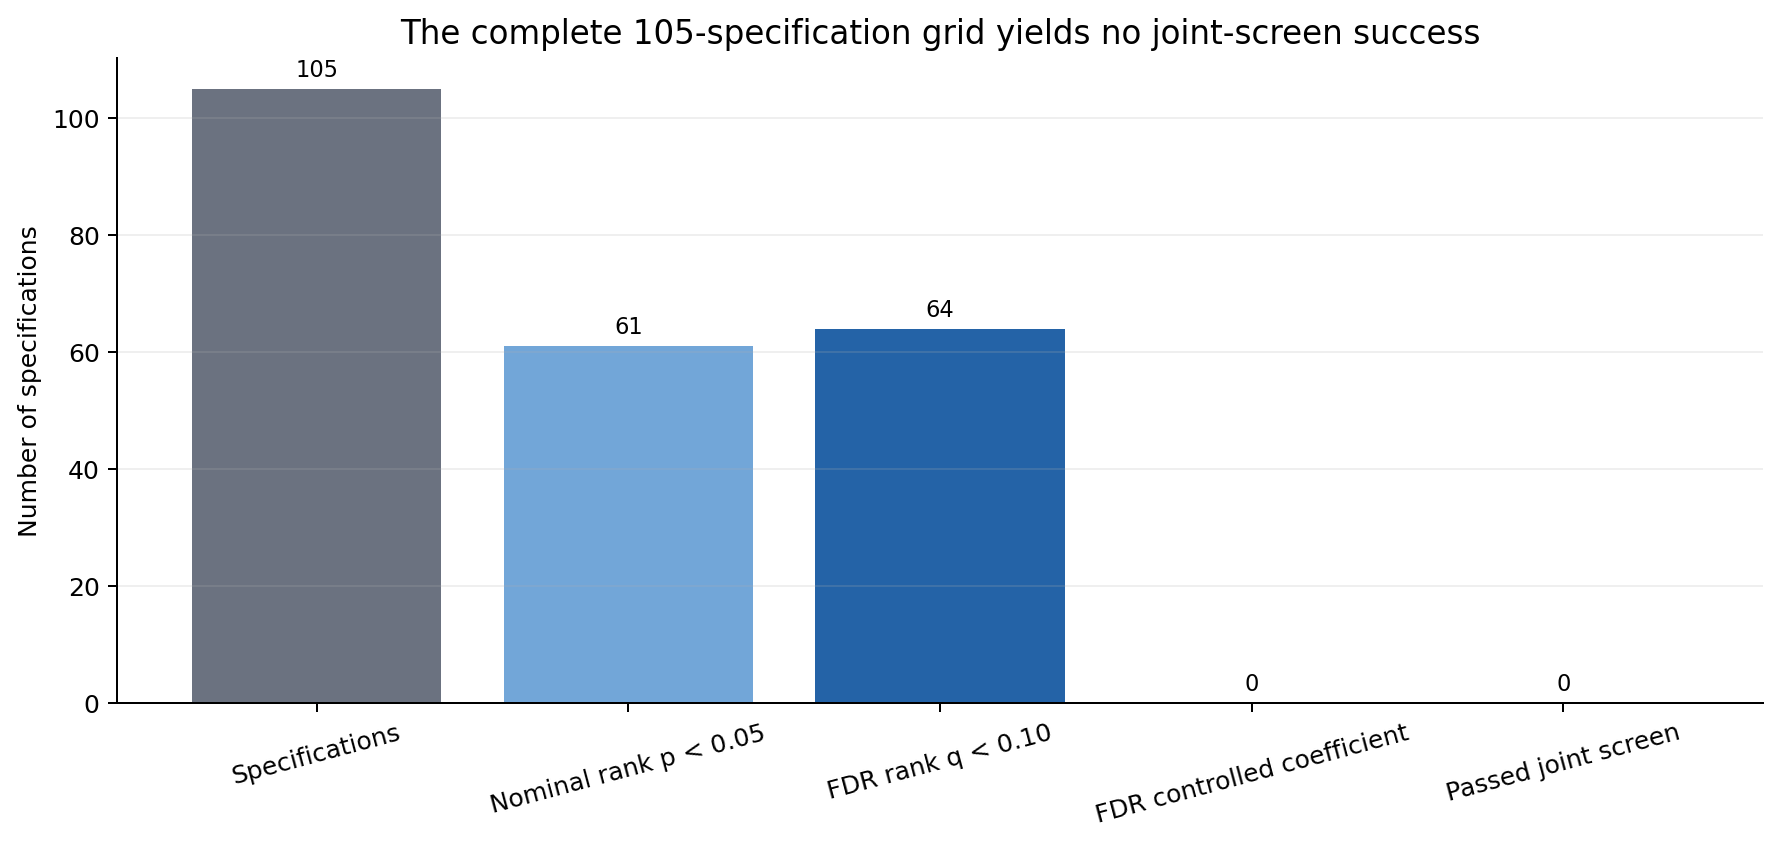

**Zero of 105 specifications passed.** This is the central event-study result and should be reported directly rather than selecting isolated raw correlations.


## 17. What the experiment establishes—and what it does not

### Supported

- SEC filings can be converted into reproducible scenario labels with a strict evidence contract and human-auditable repairs.
- Some text-defined exposures occupy recoverable neighborhoods in holdings-embedding space.
- Different investor-behavior embeddings carry different economic relationships.
- Larger seed sets materially change propagation rankings, demonstrating why seed robustness is necessary.
- Placebo and controlled evaluations are essential because embedding geometry can produce apparently meaningful raw correlations.

### Not supported

- A general claim that holdings embeddings recover every geopolitical exposure channel.
- A robust claim that expanded Russia–Ukraine exposure scores predict invasion-event abnormal returns.
- A tradable strategy: the timing exercise is a researcher-information association test, not an implementable real-time backtest.
- Independent confirmation: V2 was frozen before V2 outcome loading, but the same event had already been studied in V1.


## 18. Limitations

1. **Precision-first retrieval may miss exposures.** A zero-passage document is unlabeled, not proven unexposed.
2. **Disclosure is selective.** Firms differ in how explicitly they describe geography, customers, and risks.
3. **10-K and 10-Q language can be stale or generic.** Earnings calls may capture more contemporaneous managerial discussion, consistent with the text sources used in both Hassan et al. and the interpretation section of Gabaix et al.
4. **Directional labels are channel-level.** Within-channel heterogeneity may be richer than a single expected sign.
5. **Seed samples remain modest.** Some channels have only 13–22 firm–channel seeds.
6. **The shuffled placebo is unmatched.** A stronger robustness check should match pseudo-seeds on industry and size.
7. **Multiple hypotheses are dependent.** Benjamini–Hochberg is reported as a transparent FDR adjustment, but models, windows, and channels are correlated.
8. **One event cannot establish generality.** A held-out event designed before returns are opened is necessary.


## 19. Recommended next experiment

The next high-value test is a genuinely held-out geopolitical event. One candidate is the October 2023 Israel–Hamas shock, using 2023Q3 holdings embeddings and filings available before October 7, 2023. Before loading returns, the study should freeze:

- the event date and information cutoff;
- the firm universe and document-selection rule;
- channel definitions and expected directions;
- the retrieval dictionary, OpenAI prompt, model, and schema;
- evidence-adjudication rules;
- propagation representations and seed aggregation;
- matched and unmatched placebo designs; and
- event windows, controls, multiple-testing family, and decision thresholds.

The immediate robustness addition should be industry-and-size-matched shuffled seeds. That test can be added without changing any labels or event outcomes and will determine whether the current unrestricted placebo is too dissimilar from the real seed firms.


## 20. Reproducibility map

| Stage | Notebook | Principal frozen artifacts |
|---|---|---|
| Original text proof of concept | [`02_Text_Exposure_Pipeline.ipynb`](02_Text_Exposure_Pipeline.ipynb) | V1 seeds and evidence audit |
| Expanded corpus and labels | [`02B_Text_Corpus_Expansion.ipynb`](02B_Text_Corpus_Expansion.ipynb) | `text_expansion_v2/results/expanded_exposure_panel_final.parquet` |
| Original embedding expansion | [`03_Embedding_Expansion.ipynb`](03_Embedding_Expansion.ipynb) | `embedding_expansion/` |
| Expanded propagation | [`03B_Expanded_Label_Propagation.ipynb`](03B_Expanded_Label_Propagation.ipynb) | `embedding_expansion_v2/` and `embedding_expansion_freeze_v2.json` |
| Original event study | [`04_Event_Study_Evaluation.ipynb`](04_Event_Study_Evaluation.ipynb) | `event_study/` |
| Expanded event evaluation | [`04B_Expanded_Label_Event_Study.ipynb`](04B_Expanded_Label_Event_Study.ipynb) | `event_study_v2/` and `event_study_evaluated_v2.json` |

The raw filings, normalized documents, API responses, prompt/schema hashes, evidence adjudication, embedding scores, placebo panels, CARs, result grids, and output inventories remain stored locally under `geopolitical_exposure/`.


## References

- Benjamini, Y., and Y. Hochberg. 1995. “Controlling the False Discovery Rate: A Practical and Powerful Approach to Multiple Testing.” *Journal of the Royal Statistical Society: Series B* 57(1): 289–300. [DOI](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x).
- Campbell, J. Y., A. W. Lo, and A. C. MacKinlay. 1997. “Event-Study Analysis.” In *The Econometrics of Financial Markets*, 149–180. Princeton University Press. [DOI](https://doi.org/10.1515/9781400830213-008).
- Gabaix, X., R. S. J. Koijen, R. J. Richmond, and M. Yogo. 2026. “Asset and Investor Embeddings.” July 16, 2026. [SSRN](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5212742); [DOI](https://doi.org/10.2139/ssrn.5212742).
- Hassan, T. A., S. Hollander, L. van Lent, and A. Tahoun. 2019. “Firm-Level Political Risk: Measurement and Effects.” *Quarterly Journal of Economics* 134(4): 2135–2202. [DOI](https://doi.org/10.1093/qje/qjz021).
- MacKinlay, A. C. 1997. “Event Studies in Economics and Finance.” *Journal of Economic Literature* 35(1): 13–39. [EconPapers record](https://econpapers.repec.org/article/aeajeclit/v_3a35_3ay_3a1997_3ai_3a1_3ap_3a13-39.htm).
- OpenAI. “Create a Model Response” and structured JSON-schema output documentation. [Responses API](https://developers.openai.com/api/reference/cli/resources/responses/methods/create).
- U.S. Securities and Exchange Commission. “Developer Resources.” [SEC EDGAR developer documentation](https://www.sec.gov/about/developer-resources).
